# Demo 3 — Ontology / Concept Vector → Spherical VAE

这个 notebook 对应教授提出的第三个方向：

\[
\text{word}
\rightarrow
\text{ontology concepts}
\rightarrow
\text{concept vector}
\rightarrow
\text{Spherical VAE}
\rightarrow
\text{spherical latent}
\rightarrow
\text{reconstructed concept vector}
\]

这个方向和 Character VAE 的区别是：

- Character VAE 的信息来源是 **拼写 / morphology**；
- Ontology VAE 的信息来源是 **显式 concept hierarchy**。

例如：

```text
tiger
→ animal
→ mammal
→ carnivore
→ feline
```

```text
lion
→ animal
→ mammal
→ carnivore
→ feline
```

因此 `tiger` 和 `lion` 即使字符完全不同，concept vector 仍然会非常相似。

这个 demo 的目标不是做一个完整 ontology embedding 系统，而是做一个 **proof of concept**：
验证 ontology concept representation 是否可以像 MNIST / character matrix 一样直接进入 Spherical VAE。


## 0. 与教授思路对应的研究问题

这里测试的是：

> 如果输入不来自 Word2Vec 或文本上下文，而来自 ontology，
> Spherical VAE 能否把具有相似概念结构的词组织到相近的球面区域？

需要注意：

> 这种方法学习到的语义主要来自 ontology，而不是 corpus。

因此它更接近：

\[
\text{ontology embedding}
\]

而不是传统的：

\[
\text{corpus-based word embedding}
\]

这正是这个方案与前两个方案在研究问题上的核心区别。


In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from IPython.display import display

SEED = 42
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)


Device: cuda


# 1. 构造一个小型 ontology

为了让实验完全自包含，这里使用一个小型人工 ontology。

每个词对应一组 concepts。

例如：

```text
tiger
→ entity
→ living_thing
→ animal
→ vertebrate
→ mammal
→ carnivore
→ feline
→ big_cat
```

而：

```text
lion
→ entity
→ living_thing
→ animal
→ vertebrate
→ mammal
→ carnivore
→ feline
→ big_cat
```

所以它们共享大量 concept dimensions。


## Important correction: shared hierarchy + distinct leaf concept

在 ontology representation 中，两个相近词应该：

\[
x_a \approx x_b
\]

但不能：

\[
x_a = x_b
\]

例如 `tiger` 和 `lion` 应该共享：

```text
animal → mammal → carnivore → feline → big_cat → panthera
```

但最后必须分成不同的 leaf concepts：

```text
panthera
├── tiger_species
└── lion_species
```

这样它们会保持高度相似，同时 relation angle 不会退化成 \(0^\circ\)。

同样的修正也应用于：

- Italy / France / Germany
- Rome / Paris / Berlin
- vehicle entities
- food entities

这比仅仅在 `log_map` 里跳过报错更重要，因为它修正了 ontology representation 本身。


In [2]:
ONTOLOGY = {
    # ========================================================
    # Animals
    # Shared ancestors + distinct leaf/entity concepts.
    # This avoids tiger/lion becoming exactly identical inputs.
    # ========================================================
    "tiger": {
        "entity", "living_thing", "animal", "vertebrate",
        "mammal", "carnivore", "feline", "big_cat", "panthera",
        "wild_animal", "tiger_species"
    },
    "lion": {
        "entity", "living_thing", "animal", "vertebrate",
        "mammal", "carnivore", "feline", "big_cat", "panthera",
        "wild_animal", "lion_species"
    },
    "cat": {
        "entity", "living_thing", "animal", "vertebrate",
        "mammal", "carnivore", "feline", "small_cat",
        "domestic_animal", "cat_species"
    },
    "dog": {
        "entity", "living_thing", "animal", "vertebrate",
        "mammal", "carnivore", "canine", "domestic_animal",
        "dog_species"
    },
    "wolf": {
        "entity", "living_thing", "animal", "vertebrate",
        "mammal", "carnivore", "canine", "wild_animal",
        "wolf_species"
    },
    "horse": {
        "entity", "living_thing", "animal", "vertebrate",
        "mammal", "herbivore", "domestic_animal",
        "equine", "horse_species"
    },
    "eagle": {
        "entity", "living_thing", "animal", "vertebrate",
        "bird", "carnivore", "flying_animal",
        "eagle_species"
    },

    # ========================================================
    # Geographic / political concepts
    # Countries share country/europe, but each has a distinct
    # leaf/entity concept and a regional branch.
    # ========================================================
    "italy": {
        "entity", "place", "country", "europe", "nation_state",
        "southern_europe", "italy_entity"
    },
    "france": {
        "entity", "place", "country", "europe", "nation_state",
        "western_europe", "france_entity"
    },
    "germany": {
        "entity", "place", "country", "europe", "nation_state",
        "central_europe", "germany_entity"
    },

    "rome": {
        "entity", "place", "city", "capital_city", "europe",
        "southern_europe", "located_in_italy", "rome_entity"
    },
    "paris": {
        "entity", "place", "city", "capital_city", "europe",
        "western_europe", "located_in_france", "paris_entity"
    },
    "berlin": {
        "entity", "place", "city", "capital_city", "europe",
        "central_europe", "located_in_germany", "berlin_entity"
    },

    # ========================================================
    # Vehicles
    # ========================================================
    "car": {
        "entity", "artifact", "vehicle", "land_vehicle",
        "motor_vehicle", "private_transport", "car_entity"
    },
    "bus": {
        "entity", "artifact", "vehicle", "land_vehicle",
        "motor_vehicle", "public_transport", "bus_entity"
    },
    "train": {
        "entity", "artifact", "vehicle", "land_vehicle",
        "rail_vehicle", "public_transport", "train_entity"
    },
    "plane": {
        "entity", "artifact", "vehicle", "air_vehicle",
        "motor_vehicle", "plane_entity"
    },

    # ========================================================
    # Food
    # ========================================================
    "apple": {
        "entity", "physical_object", "food", "fruit",
        "plant_product", "apple_entity"
    },
    "orange": {
        "entity", "physical_object", "food", "fruit",
        "plant_product", "citrus", "orange_entity"
    },
    "carrot": {
        "entity", "physical_object", "food", "vegetable",
        "plant_product", "root_vegetable", "carrot_entity"
    },
}

WORDS = sorted(ONTOLOGY.keys())

ALL_CONCEPTS = sorted(
    set().union(
        *ONTOLOGY.values()
    )
)

concept_to_idx = {
    concept: idx
    for idx, concept in enumerate(ALL_CONCEPTS)
}

idx_to_concept = {
    idx: concept
    for concept, idx in concept_to_idx.items()
}

print("Words:", len(WORDS))
print("Concept dimensions:", len(ALL_CONCEPTS))

display(
    pd.DataFrame({
        "concept": ALL_CONCEPTS
    })
)

# Check whether any two words still have exactly the same ontology input.
duplicate_pairs = []

for i, word_a in enumerate(WORDS):
    for word_b in WORDS[i + 1:]:
        if ONTOLOGY[word_a] == ONTOLOGY[word_b]:
            duplicate_pairs.append(
                (word_a, word_b)
            )

print("Exact duplicate ontology inputs:", duplicate_pairs)


Words: 20
Concept dimensions: 64


,concept
0,air_vehicle
1,animal
2,apple_entity
3,artifact
4,berlin_entity
...,...
59,vehicle
60,vertebrate
61,western_europe
62,wild_animal


Exact duplicate ontology inputs: []


# 2. Concept vector

每个词使用一个 multi-hot concept vector：

\[
x_w\in\{0,1\}^{|C|}
\]

如果单词属于某个 concept，对应维度为 1。

例如 `tiger` 和 `lion` 会共享：

- animal
- mammal
- carnivore
- feline
- big_cat
- ...

因此输入层面已经存在显式 semantic structure。


In [3]:
def concept_vector(word):
    vector = np.zeros(
        len(ALL_CONCEPTS),
        dtype=np.float32,
    )

    for concept in ONTOLOGY[word]:
        vector[
            concept_to_idx[concept]
        ] = 1.0

    return vector


concept_matrix = np.vstack([
    concept_vector(word)
    for word in WORDS
])

concept_df = pd.DataFrame(
    concept_matrix,
    index=WORDS,
    columns=ALL_CONCEPTS,
)

display(
    concept_df
)


,air_vehicle,animal,apple_entity,artifact,berlin_entity,big_cat,bird,bus_entity,canine,capital_city,...,small_cat,southern_europe,tiger_species,train_entity,vegetable,vehicle,vertebrate,western_europe,wild_animal,wolf_species
apple,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
berlin,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
bus,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
car,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
carrot,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
cat,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
dog,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
eagle,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
france,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
germany,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 输入空间中先看一下 ontology similarity

这里先不用 VAE，直接计算 concept vector 的 cosine similarity。

这能让我们确认：

> tiger 和 lion 的接近，是由 ontology 明确提供的，
> 不是模型自己从文本中学到的。


In [4]:
def cosine_similarity(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)

    denom = (
        np.linalg.norm(a)
        * np.linalg.norm(b)
    )

    if denom < 1e-12:
        return 0.0

    return float(
        np.dot(a, b) / denom
    )


PAIR_CHECKS = [
    ("tiger", "lion"),
    ("tiger", "cat"),
    ("tiger", "dog"),
    ("cat", "dog"),
    ("italy", "france"),
    ("rome", "paris"),
    ("rome", "italy"),
    ("car", "bus"),
    ("car", "apple"),
]

rows = []

for first, second in PAIR_CHECKS:
    rows.append({
        "word_1": first,
        "word_2": second,
        "shared_concepts": len(
            ONTOLOGY[first]
            & ONTOLOGY[second]
        ),
        "concept_cosine": cosine_similarity(
            concept_vector(first),
            concept_vector(second),
        ),
    })

display(
    pd.DataFrame(rows)
    .sort_values(
        "concept_cosine",
        ascending=False,
    )
)


,word_1,word_2,shared_concepts,concept_cosine
0,tiger,lion,10,0.909091
3,cat,dog,7,0.737865
4,italy,france,5,0.714286
7,car,bus,5,0.714286
1,tiger,cat,7,0.667424
5,rome,paris,5,0.625000
2,tiger,dog,6,0.603023
6,rome,italy,4,0.534522
8,car,apple,1,0.154303


# 3. Spherical VAE

输入：

\[
x_w = \text{concept vector}
\]

Encoder 输出一个方向并归一化到单位球面：

\[
z_w\in S^{d-1}
\]

Decoder 重新预测 concept vector。

Loss：

\[
L
=
L_{\text{reconstruction}}
+
\beta L_{\text{Riesz}}
\]

其中 reconstruction 使用 binary cross entropy，因为 concept vector 是 multi-hot。


In [5]:
LATENT_DIM = 8
HIDDEN_DIM = 128

EPOCHS = 400
LEARNING_RATE = 1e-3
BETA_RIESZ = 0.001
SAMPLE_ALPHA = 0.08


def riesz_energy(points, s=1.0):
    if points.size(0) < 2:
        return torch.zeros(
            (),
            device=points.device,
        )

    distances = torch.cdist(
        points,
        points,
    )

    mask = torch.triu(
        torch.ones_like(
            distances,
            dtype=torch.bool,
        ),
        diagonal=1,
    )

    valid = distances[mask]

    return torch.mean(
        1.0
        / torch.clamp(
            valid,
            min=1e-4,
        ).pow(s)
    )


class OntologyDataset(Dataset):
    def __init__(self, words):
        self.words = list(words)

    def __len__(self):
        return len(self.words)

    def __getitem__(self, index):
        word = self.words[index]
        vector = concept_vector(word)

        return (
            torch.tensor(
                vector,
                dtype=torch.float32,
            ),
            word,
        )


class OntologySphericalVAE(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dim,
        latent_dim,
        sample_alpha=0.08,
    ):
        super().__init__()

        self.sample_alpha = sample_alpha

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def encode_direction(self, x):
        raw = self.encoder(x)

        return F.normalize(
            raw,
            p=2,
            dim=-1,
            eps=1e-8,
        )

    def sample_on_sphere(
        self,
        mean_direction,
    ):
        noise = torch.randn_like(
            mean_direction
        )

        tangent = (
            noise
            - (
                noise
                * mean_direction
            ).sum(
                dim=-1,
                keepdim=True,
            )
            * mean_direction
        )

        tangent = F.normalize(
            tangent,
            p=2,
            dim=-1,
            eps=1e-8,
        )

        theta = (
            self.sample_alpha
            * torch.rand(
                mean_direction.size(0),
                1,
                device=mean_direction.device,
            )
        )

        z = (
            mean_direction
            * torch.cos(theta)
            + tangent
            * torch.sin(theta)
        )

        return F.normalize(
            z,
            p=2,
            dim=-1,
            eps=1e-8,
        )

    def decode_logits(self, z):
        return self.decoder(z)

    def forward(self, x):
        mean_direction = (
            self.encode_direction(x)
        )

        z = self.sample_on_sphere(
            mean_direction
        )

        logits = self.decode_logits(z)

        return (
            logits,
            mean_direction,
            z,
        )


dataset = OntologyDataset(WORDS)

loader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=True,
)

model = OntologySphericalVAE(
    input_dim=len(ALL_CONCEPTS),
    hidden_dim=HIDDEN_DIM,
    latent_dim=LATENT_DIM,
    sample_alpha=SAMPLE_ALPHA,
).to(DEVICE)

print(model)


OntologySphericalVAE(
  (encoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=8, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
  )
)


# 4. Training


Epoch   1 | loss=0.6931 | reconstruction=0.6906 | riesz=2.5303
Epoch  50 | loss=0.2215 | reconstruction=0.2201 | riesz=1.4422
Epoch 100 | loss=0.1122 | reconstruction=0.1108 | riesz=1.3656
Epoch 150 | loss=0.0590 | reconstruction=0.0579 | riesz=1.0897
Epoch 200 | loss=0.0199 | reconstruction=0.0191 | riesz=0.7790
Epoch 250 | loss=0.0076 | reconstruction=0.0068 | riesz=0.8415
Epoch 300 | loss=0.0034 | reconstruction=0.0026 | riesz=0.7415
Epoch 350 | loss=0.0022 | reconstruction=0.0014 | riesz=0.8140
Epoch 400 | loss=0.0015 | reconstruction=0.0008 | riesz=0.7815


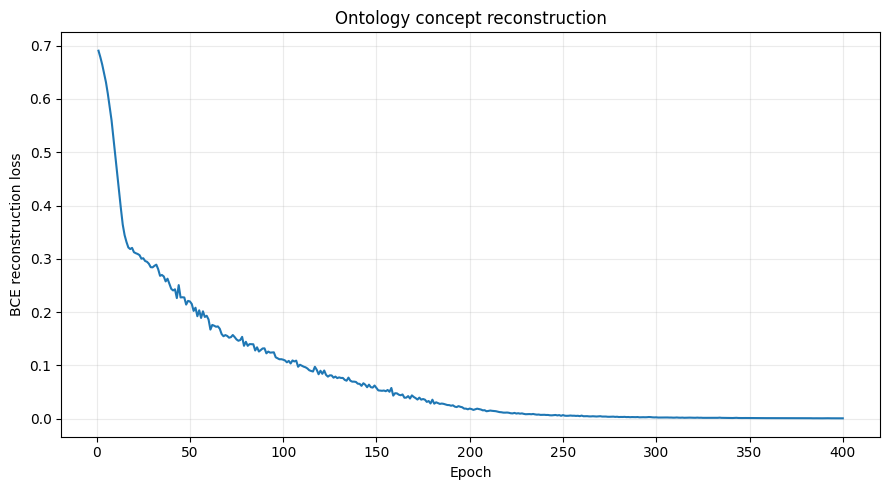

In [6]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

history = []

for epoch in range(EPOCHS):
    model.train()

    total_loss = 0.0
    total_reconstruction = 0.0
    total_riesz = 0.0
    n_steps = 0

    for batch_x, _ in loader:
        batch_x = batch_x.to(
            DEVICE
        )

        optimizer.zero_grad()

        (
            logits,
            mean_direction,
            _,
        ) = model(batch_x)

        reconstruction = (
            F.binary_cross_entropy_with_logits(
                logits,
                batch_x,
            )
        )

        riesz = riesz_energy(
            mean_direction
        )

        loss = (
            reconstruction
            + BETA_RIESZ
            * riesz
        )

        loss.backward()
        optimizer.step()

        total_loss += float(
            loss.detach().cpu()
        )

        total_reconstruction += float(
            reconstruction.detach().cpu()
        )

        total_riesz += float(
            riesz.detach().cpu()
        )

        n_steps += 1

    row = {
        "epoch": epoch + 1,
        "loss": total_loss / n_steps,
        "reconstruction": (
            total_reconstruction
            / n_steps
        ),
        "riesz": (
            total_riesz
            / n_steps
        ),
    }

    history.append(row)

    if (
        epoch == 0
        or (epoch + 1) % 50 == 0
    ):
        print(
            f"Epoch {epoch+1:3d} | "
            f"loss={row['loss']:.4f} | "
            f"reconstruction="
            f"{row['reconstruction']:.4f} | "
            f"riesz={row['riesz']:.4f}"
        )

history = pd.DataFrame(history)

plt.figure(figsize=(9, 5))
plt.plot(
    history["epoch"],
    history["reconstruction"],
)
plt.xlabel("Epoch")
plt.ylabel("BCE reconstruction loss")
plt.title(
    "Ontology concept reconstruction"
)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# 5. Encode words into the spherical latent space


In [7]:
model.eval()

word_latents = {}

with torch.no_grad():
    for word in WORDS:
        x = torch.tensor(
            concept_vector(word),
            dtype=torch.float32,
            device=DEVICE,
        ).unsqueeze(0)

        z = model.encode_direction(
            x
        )[0].cpu().numpy()

        word_latents[word] = z


def spherical_distance(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)

    a = a / np.linalg.norm(a)
    b = b / np.linalg.norm(b)

    return np.arccos(
        np.clip(
            np.dot(a, b),
            -1.0,
            1.0,
        )
    )


# 6. 关键测试：语义相近词在球面上的角度

这里的 angle 和之前一样：

\[
\theta(w_1,w_2)
=
\arccos(z_{w_1}^{\top}z_{w_2})
\]

单位转换成 degree。

我们重点比较：

- `tiger ↔ lion`
- `tiger ↔ cat`
- `tiger ↔ dog`
- `italy ↔ france`
- `rome ↔ paris`
- `car ↔ bus`
- `car ↔ apple`

如果 ontology representation 有效，那么共享 concepts 越多的词，通常应该拥有更小的 spherical angle。


In [8]:
angle_rows = []

for first, second in PAIR_CHECKS:
    angle = spherical_distance(
        word_latents[first],
        word_latents[second],
    )

    angle_rows.append({
        "word_1": first,
        "word_2": second,
        "shared_concepts": len(
            ONTOLOGY[first]
            & ONTOLOGY[second]
        ),
        "input_concept_cosine": (
            cosine_similarity(
                concept_vector(first),
                concept_vector(second),
            )
        ),
        "latent_angle_deg": float(
            np.degrees(angle)
        ),
    })

angle_df = (
    pd.DataFrame(angle_rows)
    .sort_values(
        "latent_angle_deg"
    )
)

display(angle_df)


,word_1,word_2,shared_concepts,input_concept_cosine,latent_angle_deg
1,tiger,cat,7,0.667424,45.731649
7,car,bus,5,0.714286,46.581992
0,tiger,lion,10,0.909091,49.101213
6,rome,italy,4,0.534522,53.557848
3,cat,dog,7,0.737865,53.607107
4,italy,france,5,0.714286,57.539617
5,rome,paris,5,0.625000,63.623648
2,tiger,dog,6,0.603023,76.130171
8,car,apple,1,0.154303,90.252765


# 7. Nearest neighbours in spherical latent space


In [9]:
def nearest_words(
    query_word,
    k=6,
):
    query = word_latents[
        query_word
    ]

    rows = []

    for word, vector in (
        word_latents.items()
    ):
        if word == query_word:
            continue

        angle = spherical_distance(
            query,
            vector,
        )

        rows.append({
            "word": word,
            "angle_deg": float(
                np.degrees(angle)
            ),
            "shared_concepts": len(
                ONTOLOGY[query_word]
                & ONTOLOGY[word]
            ),
        })

    return (
        pd.DataFrame(rows)
        .sort_values("angle_deg")
        .head(k)
        .reset_index(drop=True)
    )


for query in [
    "tiger",
    "lion",
    "rome",
    "italy",
    "car",
]:
    print("\nQuery:", query)
    display(
        nearest_words(
            query,
            k=6,
        )
    )



Query: tiger


,word,angle_deg,shared_concepts
0,cat,45.731649,7
1,lion,49.101213,10
2,carrot,61.685036,1
3,wolf,67.990241,7
4,apple,74.209939,1
5,dog,76.130171,6



Query: lion


,word,angle_deg,shared_concepts
0,tiger,49.101213,10
1,car,54.654575,1
2,eagle,57.535439,5
3,plane,58.334716,1
4,wolf,69.916825,7
5,bus,82.178485,1



Query: rome


,word,angle_deg,shared_concepts
0,horse,42.756055,1
1,italy,53.557848,4
2,paris,63.623648,5
3,bus,68.576153,1
4,eagle,68.992023,1
5,berlin,69.609835,5



Query: italy


,word,angle_deg,shared_concepts
0,train,52.350307,1
1,rome,53.557848,4
2,berlin,55.211851,3
3,france,57.539617,5
4,orange,58.593443,1
5,germany,60.720169,5



Query: car


,word,angle_deg,shared_concepts
0,bus,46.581992,5
1,plane,49.902223,4
2,lion,54.654575,1
3,train,58.467118,4
4,carrot,63.891153,1
5,france,80.781066,1


# 8. Reconstruction of ontology concepts

Decoder 不重构单词拼写，而是重构 concept vector。

例如输入 `tiger` 后，我们希望 decoder 恢复类似：

```text
animal
mammal
carnivore
feline
big_cat
...
```

这也直接体现了这个方向的本质：

> 模型重构的是 ontology knowledge，而不是文本中的语言形式。


In [10]:
def decode_concepts(
    latent,
    threshold=0.5,
):
    z = torch.tensor(
        latent,
        dtype=torch.float32,
        device=DEVICE,
    ).unsqueeze(0)

    with torch.no_grad():
        logits = model.decode_logits(
            z
        )[0]

        probs = torch.sigmoid(
            logits
        ).cpu().numpy()

    predicted = [
        ALL_CONCEPTS[i]
        for i, p in enumerate(probs)
        if p >= threshold
    ]

    ranked = sorted(
        [
            (ALL_CONCEPTS[i], float(p))
            for i, p in enumerate(probs)
        ],
        key=lambda x: x[1],
        reverse=True,
    )

    return predicted, ranked


reconstruction_rows = []

for word in [
    "tiger",
    "lion",
    "cat",
    "dog",
    "rome",
    "italy",
    "car",
]:
    predicted, ranked = (
        decode_concepts(
            word_latents[word],
            threshold=0.5,
        )
    )

    true_set = ONTOLOGY[word]
    pred_set = set(predicted)

    intersection = (
        true_set & pred_set
    )

    union = (
        true_set | pred_set
    )

    jaccard = (
        len(intersection)
        / max(len(union), 1)
    )

    reconstruction_rows.append({
        "word": word,
        "true_concepts": ", ".join(
            sorted(true_set)
        ),
        "predicted_concepts": ", ".join(
            sorted(pred_set)
        ),
        "jaccard": jaccard,
    })

display(
    pd.DataFrame(
        reconstruction_rows
    )
)


,word,true_concepts,predicted_concepts,jaccard
0,tiger,"animal, big_cat, carnivore, entity, feline, li...","animal, big_cat, carnivore, entity, feline, li...",1.0
1,lion,"animal, big_cat, carnivore, entity, feline, li...","animal, big_cat, carnivore, entity, feline, li...",1.0
2,cat,"animal, carnivore, cat_species, domestic_anima...","animal, carnivore, cat_species, domestic_anima...",1.0
3,dog,"animal, canine, carnivore, dog_species, domest...","animal, canine, carnivore, dog_species, domest...",1.0
4,rome,"capital_city, city, entity, europe, located_in...","capital_city, city, entity, europe, located_in...",1.0
5,italy,"country, entity, europe, italy_entity, nation_...","country, entity, europe, italy_entity, nation_...",1.0
6,car,"artifact, car_entity, entity, land_vehicle, mo...","artifact, car_entity, entity, land_vehicle, mo...",1.0


# 9. 3D visualization of ontology latent points

真实 latent 是：

\[
S^{7}
\]

这里使用 PCA 只做 3D 可视化。

因此：

> 下面的图只用于观察 cluster，不用于计算真实 spherical angle。

真实 angle 仍然在原始 8D spherical latent 中计算。


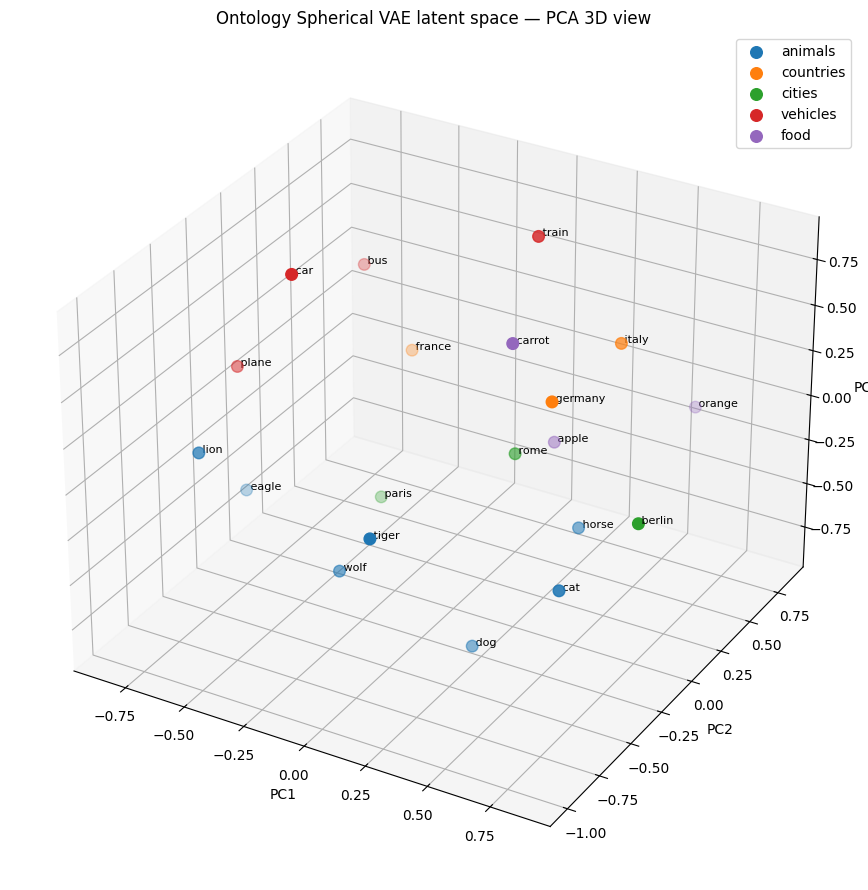

In [11]:
from sklearn.decomposition import PCA

latent_matrix = np.vstack([
    word_latents[word]
    for word in WORDS
])

pca = PCA(
    n_components=3
)

latent_3d = pca.fit_transform(
    latent_matrix
)

word_to_3d = {
    word: latent_3d[i]
    for i, word in enumerate(WORDS)
}


GROUPS = {
    "animals": [
        "tiger", "lion", "cat",
        "dog", "wolf", "horse", "eagle"
    ],
    "countries": [
        "italy", "france", "germany"
    ],
    "cities": [
        "rome", "paris", "berlin"
    ],
    "vehicles": [
        "car", "bus", "train", "plane"
    ],
    "food": [
        "apple", "orange", "carrot"
    ],
}

fig = plt.figure(
    figsize=(11, 9)
)

ax = fig.add_subplot(
    111,
    projection="3d",
)

for group_name, group_words in GROUPS.items():
    coords = np.vstack([
        word_to_3d[word]
        for word in group_words
    ])

    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        coords[:, 2],
        s=70,
        label=group_name,
    )

    for word, point in zip(
        group_words,
        coords,
    ):
        ax.text(
            point[0],
            point[1],
            point[2],
            " " + word,
            fontsize=8,
        )

ax.set_title(
    "Ontology Spherical VAE latent space — PCA 3D view"
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.legend()
plt.tight_layout()
plt.show()


# 10. Relation-guided motion on ontology latent space

这里仍然保留你前面实验使用的 spherical geometry：

\[
v_{ab}
=
\log_a(b)
\]

然后沿 relation direction 移动：

\[
\gamma(t)
=
\operatorname{Exp}_a
\left(
t\alpha v_{ab}
\right)
\]

按照你目前的实验设置，只测试：

\[
\alpha=0.5,\quad 1.5
\]

也就是：

- `0.5×`：走原 relation angle 的一半；
- `1.5×`：越过原 target，再继续半个 relation angle。


In [12]:
EPS = 1e-10
GEOM_TOL = 1e-7


def normalize_vector(v):
    v = np.asarray(
        v,
        dtype=np.float64,
    )

    n = np.linalg.norm(v)

    if n < EPS:
        raise ValueError(
            "Near-zero vector."
        )

    return v / n


def log_map(x, y):
    """
    Stable log map on the unit sphere.

    For two identical / numerically indistinguishable points,
    the geodesic displacement is the zero tangent vector.
    """
    x = normalize_vector(x)
    y = normalize_vector(y)

    c = np.clip(
        np.dot(x, y),
        -1.0,
        1.0,
    )

    theta = np.arccos(c)

    if theta < GEOM_TOL:
        return np.zeros_like(x)

    direction = (
        y
        - c * x
    )

    direction_norm = np.linalg.norm(
        direction
    )

    if direction_norm < GEOM_TOL:
        return np.zeros_like(x)

    direction = (
        direction
        / direction_norm
    )

    return theta * direction


def exp_map(x, tangent):
    x = normalize_vector(x)

    tangent = np.asarray(
        tangent,
        dtype=np.float64,
    )

    tangent = (
        tangent
        - np.dot(
            tangent,
            x,
        ) * x
    )

    norm = np.linalg.norm(
        tangent
    )

    if norm < GEOM_TOL:
        return x.copy()

    return normalize_vector(
        np.cos(norm) * x
        + np.sin(norm)
        * tangent / norm
    )


ANGLE_SCALES = [
    0.5,
    1.5,
]


RELATIONS_TO_TEST = [
    ("tiger", "lion"),
    ("cat", "dog"),
    ("italy", "france"),
    ("rome", "paris"),
    ("car", "bus"),
]


motion_rows = []
skipped_relations = []

for source_word, target_word in (
    RELATIONS_TO_TEST
):
    source = word_latents[
        source_word
    ]

    target = word_latents[
        target_word
    ]

    relation = log_map(
        source,
        target,
    )

    relation_norm = np.linalg.norm(
        relation
    )

    # Robust handling: if two latent points still collapse
    # numerically, skip the motion instead of crashing.
    if relation_norm < GEOM_TOL:
        skipped_relations.append({
            "relation": (
                f"{source_word}→"
                f"{target_word}"
            ),
            "reason": (
                "latent points are identical "
                "or almost identical"
            ),
        })

        print(
            f"Skip {source_word}→{target_word}: "
            "zero / near-zero relation."
        )

        continue

    relation_angle_deg = float(
        np.degrees(
            relation_norm
        )
    )

    for scale in ANGLE_SCALES:
        endpoint = exp_map(
            source,
            scale * relation,
        )

        predicted_concepts, ranked = (
            decode_concepts(
                endpoint,
                threshold=0.5,
            )
        )

        nearest = []

        for word, vector in (
            word_latents.items()
        ):
            distance = spherical_distance(
                endpoint,
                vector,
            )

            nearest.append(
                (
                    word,
                    float(
                        np.degrees(
                            distance
                        )
                    ),
                )
            )

        nearest = sorted(
            nearest,
            key=lambda x: x[1],
        )

        motion_rows.append({
            "relation": (
                f"{source_word}→"
                f"{target_word}"
            ),
            "scale": scale,
            "relation_angle_deg": (
                relation_angle_deg
            ),
            "travelled_angle_deg": (
                scale
                * relation_angle_deg
            ),
            "nearest_word": (
                nearest[0][0]
            ),
            "nearest_angle_deg": (
                nearest[0][1]
            ),
            "decoded_concepts": (
                ", ".join(
                    predicted_concepts
                )
            ),
        })


motion_df = pd.DataFrame(
    motion_rows
)

display(
    motion_df
)

if skipped_relations:
    print("\nSkipped relations:")
    display(
        pd.DataFrame(
            skipped_relations
        )
    )


,relation,scale,relation_angle_deg,travelled_angle_deg,nearest_word,nearest_angle_deg,decoded_concepts
0,tiger→lion,0.5,49.101213,24.550606,lion,24.550606,"animal, big_cat, carnivore, entity, feline, li..."
1,tiger→lion,1.5,49.101213,73.651819,lion,24.550606,"animal, artifact, big_cat, carnivore, entity, ..."
2,cat→dog,0.5,53.607107,26.803554,cat,26.803554,"animal, canine, carnivore, cat_species, dog_sp..."
3,cat→dog,1.5,53.607107,80.410661,dog,26.803554,"animal, canine, carnivore, dog_species, entity..."
4,italy→france,0.5,57.539617,28.769809,france,28.769809,"country, entity, europe, france_entity, italy_..."
5,italy→france,1.5,57.539617,86.309426,france,28.769809,"entity, europe, place, western_europe"
6,rome→paris,0.5,63.623648,31.811824,rome,31.811824,"capital_city, city, entity, europe, located_in..."
7,rome→paris,1.5,63.623648,95.435472,paris,31.811824,"entity, europe, located_in_france, place, west..."
8,car→bus,0.5,46.581992,23.290996,bus,23.290996,"artifact, bus_entity, car_entity, entity, land..."
9,car→bus,1.5,46.581992,69.872988,bus,23.290996,"artifact, bus_entity, entity, europe, land_veh..."


# 11. 一个非常重要的解释

如果实验得到：

```text
tiger ↔ lion
```

角度很小，并不能说：

> Spherical VAE 从语言语料中学会了 tiger 和 lion 的语义关系。

更准确的说法是：

> ontology 已经告诉模型 tiger 和 lion 共享 animal / mammal / carnivore / feline 等 concepts，
> Spherical VAE 学习的是如何把这种 concept structure 压缩并组织到球面 latent space 中。

因此这个方向回答的问题是：

\[
\boxed{
\text{Can an ontology-defined concept structure be represented geometrically on a spherical latent space?}
}
\]

而不是：

\[
\boxed{
\text{Can semantic relations be discovered from corpus statistics?}
}
\]


# 12. 三个方向的区别

| 方案 | 输入信息来源 | 更容易学习什么 |
|---|---|---|
| Word2Vec / corpus | 文本上下文 | semantic relations |
| Character VAE | 字符序列 | spelling / morphology |
| Ontology VAE | ontology concepts | explicit conceptual semantics |

因此第三个方案的优点是：

- `tiger` 与 `lion` 即使拼写完全不同，也可以很接近；
- concept hierarchy 可以直接进入 spherical latent；
- 很适合测试 spherical geometry 是否能保存 hierarchy / concept similarity。

缺点是：

- semantic supervision 已经来自 ontology；
- corpus 不再是主要信息来源；
- 研究问题会更偏向 ontology embedding。
